<a href="https://colab.research.google.com/github/Richwalter/COU07506-labs/blob/main/WEEK_2_%E2%80%94_LAB_1A.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

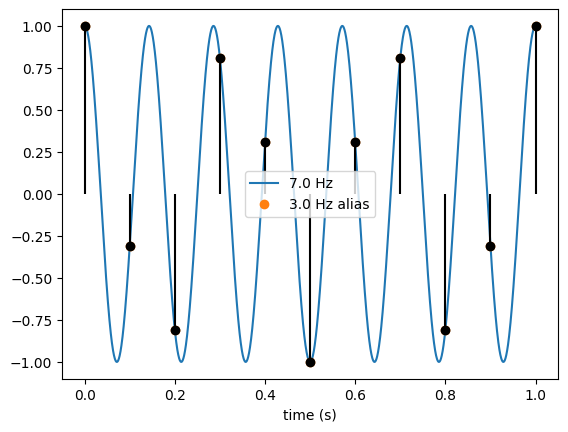

In [2]:
import numpy as np
import matplotlib.pyplot as plt

f0, fs = 7.0, 10.0
t = np.linspace(0, 1, 2000)
n = np.arange(0, int(fs)+1)
tn = n/fs

f_alias = abs(f0 - fs*round(f0/fs))

plt.plot(t, np.cos(2*np.pi*f0*t), label=f"{f0} Hz")
plt.plot(tn, np.cos(2*np.pi*f0*tn), "o",
         label=f"{f_alias} Hz alias")
plt.stem(tn, np.cos(2*np.pi*f0*tn),
         linefmt="k-", markerfmt="ko", basefmt=" ")

plt.xlabel("time (s)")
plt.legend()
plt.show()

Exception ignored in: <function Wave_write.__del__ at 0x7ae3fadb9080>
Traceback (most recent call last):
  File "/usr/lib/python3.13/wave.py", line 471, in __del__
    self.close()
  File "/usr/lib/python3.13/wave.py", line 595, in close
    self._ensure_header_written(0)
  File "/usr/lib/python3.13/wave.py", line 618, in _ensure_header_written
    self._write_header(datasize)
  File "/usr/lib/python3.13/wave.py", line 622, in _write_header
    self._file.write(b'RIFF')
ValueError: I/O operation on closed file.
Exception ignored in: <function Wave_write.__del__ at 0x7ae3fadb9080>
Traceback (most recent call last):
  File "/usr/lib/python3.13/wave.py", line 471, in __del__
    self.close()
  File "/usr/lib/python3.13/wave.py", line 595, in close
    self._ensure_header_written(0)
  File "/usr/lib/python3.13/wave.py", line 618, in _ensure_header_written
    self._write_header(datasize)
  File "/usr/lib/python3.13/wave.py", line 622, in _write_header
    self._file.write(b'RIFF')
ValueErr

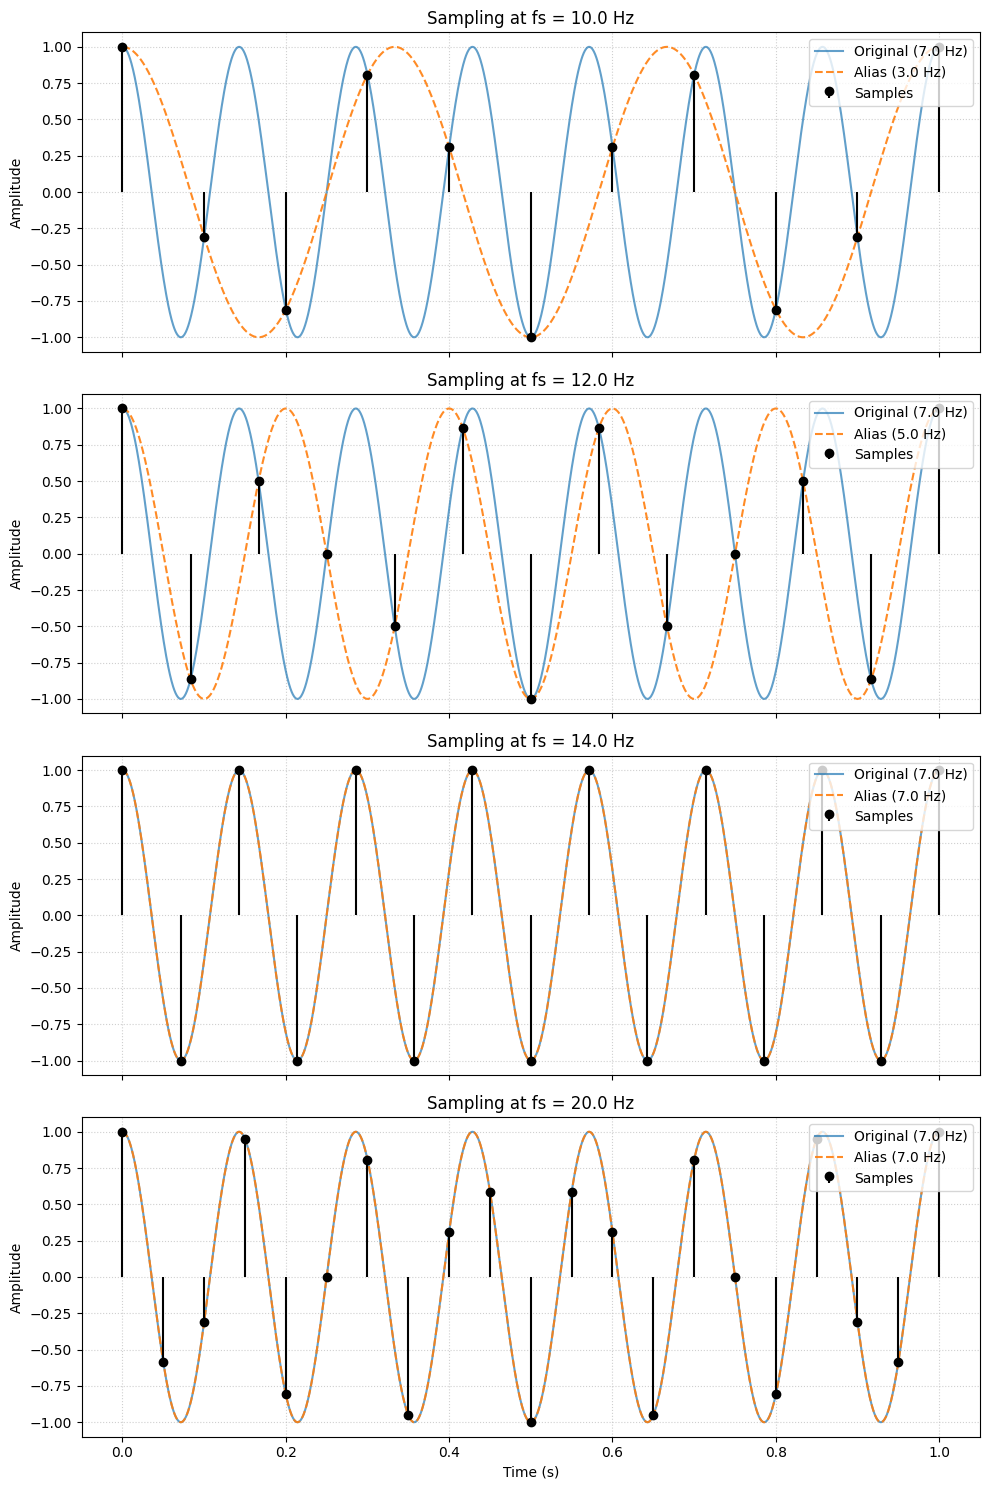

,Sampling Frequency (fs),Calculated Alias Frequency,Best k,|f0 - k*fs|
0,10.0 Hz,3.0 Hz,1,3.0 Hz
1,12.0 Hz,5.0 Hz,1,5.0 Hz
2,14.0 Hz,7.0 Hz,0,7.0 Hz
3,20.0 Hz,7.0 Hz,0,7.0 Hz


In [30]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Original signal parameters
f0 = 7.0
t = np.linspace(0, 1, 2000) # Dense time grid

# Target sampling frequencies
fs_list = [10.0, 12.0, 14.0, 20.0]
results = []

fig, axes = plt.subplots(len(fs_list), 1, figsize=(10, 15), sharex=True)

for idx, fs in enumerate(fs_list):
    # Re-calculate discrete time steps
    n = np.arange(0, int(fs) + 1)
    tn = n / fs

    # Calculated alias frequency
    f_alias = abs(f0 - fs * round(f0 / fs))

    # Analytical formula |f0 - k*fs| comparison
    # Find integer k that minimizes the difference
    k_best = round(f0 / fs)
    formula_val = abs(f0 - k_best * fs)

    results.append({
        "Sampling Frequency (fs)": f"{fs} Hz",
        "Calculated Alias Frequency": f"{f_alias} Hz",
        "Best k": k_best,
        "|f0 - k*fs|": f"{formula_val} Hz"
    })

    # Plotting
    ax = axes[idx]
    ax.plot(t, np.cos(2*np.pi*f0*t), label=f"Original ({f0} Hz)", alpha=0.7)
    ax.plot(t, np.cos(2*np.pi*f_alias*t), "--", label=f"Alias ({f_alias} Hz)", alpha=0.9)
    ax.stem(tn, np.cos(2*np.pi*f0*tn), linefmt="k-", markerfmt="ko", basefmt=" ", label="Samples")

    ax.set_title(f"Sampling at fs = {fs} Hz")
    ax.set_ylabel("Amplitude")
    ax.legend(loc="upper right")
    ax.grid(True, linestyle=":", alpha=0.6)

axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

# Display comparison table
df_results = pd.DataFrame(results)
display(df_results)

In [31]:
import os
import numpy as np
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

fname = "/content/walter.wav"
use_fallback = True

if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    x = x.astype(float)
    # Check if file has active content
    if np.max(np.abs(x)) > 0:
        # Convert stereo to mono
        x = x.mean(axis=1) if x.ndim > 1 else x
        # Normalize amplitude
        x = x / np.max(np.abs(x))
        use_fallback = False
        print(f"Loaded '{fname}' successfully. Sample rate: {fs} Hz")
    else:
        print("Warning: '/content/walter.wav' is completely silent. Falling back to synthetic chirp.")

if use_fallback:
    fs = 44100
    t = np.arange(0, 3, 1/fs)
    x = 0.5 * signal.chirp(t, 200, 3, 15000)
    print(f"Using synthetic fallback (chirp). Sample rate: {fs} Hz")

Loaded '/content/walter.wav' successfully. Sample rate: 44100 Hz


In [33]:
k = 8
new_fs = fs // k
print(f"Downsampling factor k = {k} | New sampling rate = {new_fs} Hz")

# 1. Naive downsampling (no filter)
naive_8 = x[::k]

# 2. Proper downsampling (anti-aliasing filter + downsampling)
proper_8 = signal.decimate(x, k, ftype='fir')

print("\n--- 1. Naive Downsampling (Aliased) ---")
display(Audio(naive_8, rate=new_fs))

print("\n--- 2. Proper Decimation (Filtered & Clean) ---")
display(Audio(proper_8, rate=new_fs))

Downsampling factor k = 8 | New sampling rate = 5512 Hz

--- 1. Naive Downsampling (Aliased) ---



--- 2. Proper Decimation (Filtered & Clean) ---


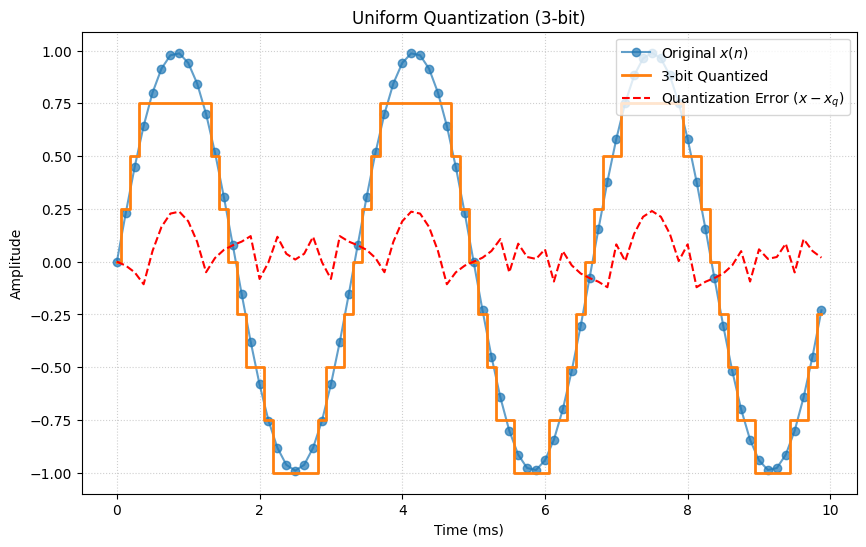

In [35]:
import numpy as np
import matplotlib.pyplot as plt

def quantize(x, bits, full_scale=1.0):
    delta = 2 * full_scale / 2**bits
    q = np.round(x / delta) * delta
    return np.clip(q, -full_scale, full_scale - delta)

# Parameters
fs = 8000
t = np.arange(0, 0.01, 1/fs)  # 10 ms interval
x = 0.99 * np.sin(2 * np.pi * 300 * t)

# 3-bit quantization
xq = quantize(x, 3)

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(t * 1e3, x, 'o-', label="Original $x(n)$", alpha=0.7)
plt.step(t * 1e3, xq, where="mid", label="3-bit Quantized", linewidth=2)
plt.plot(t * 1e3, x - xq, 'r--', label="Quantization Error ($x - x_q$)")

plt.title("Uniform Quantization (3-bit)")
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.legend(loc="upper right")
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

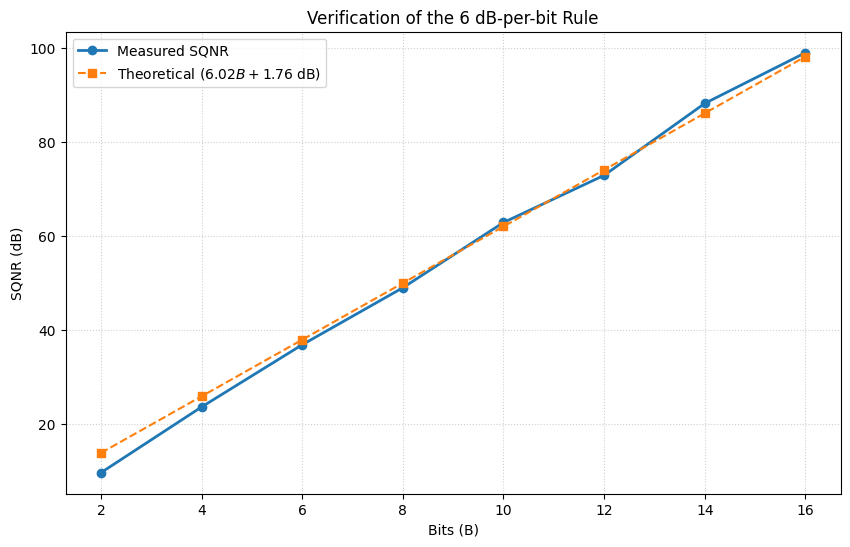

In [38]:
import numpy as np
import matplotlib.pyplot as plt

# Bit depth array
bits = np.arange(2, 17, 2)

# Compute measured SQNR for each bit depth
meas = [10 * np.log10(np.sum(x**2) / np.sum((x - quantize(x, B))**2)) for B in bits]

# Theoretical formula
theor = 6.02 * bits + 1.76

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(bits, meas, "o-", label="Measured SQNR", linewidth=2)
plt.plot(bits, theor, "s--", label="Theoretical ($6.02B + 1.76$ dB)", linewidth=1.5)

plt.title("Verification of the 6 dB-per-bit Rule")
plt.xlabel("Bits (B)")
plt.ylabel("SQNR (dB)")
plt.xticks(bits)
plt.legend(loc="upper left")
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

In [39]:
voice_bits = [4, 8, 12]

for b in voice_bits:
    xq_voice = quantize(x, b)

    # Calculate SQNR
    noise = x - xq_voice
    # Prevent division by zero if noise is somehow empty or perfectly zero
    if np.sum(noise**2) > 0:
        sqnr_voice = 10 * np.log10(np.sum(x**2) / np.sum(noise**2))
    else:
        sqnr_voice = float('inf')

    print(f"\n=== {b}-bit Quantization | Measured SQNR = {sqnr_voice:.2f} dB ===")
    display(Audio(xq_voice, rate=fs))


=== 4-bit Quantization | Measured SQNR = 23.58 dB ===



=== 8-bit Quantization | Measured SQNR = 48.93 dB ===



=== 12-bit Quantization | Measured SQNR = 72.84 dB ===


### Lab 2 Analysis & Reflection Questions

---

#### **Question 1: Explain, with a frequency-axis sketch, why the 7 Hz tone appears at 3 Hz when $f_s = 10$ Hz.**

When continuous signals are sampled, their spectral representations are periodically replicated at integer multiples of the sampling frequency ($k \cdot f_s$).

For a real sinusoid of frequency $f_0 = 7$ Hz, its continuous spectrum consists of two impulses at $\pm 7$ Hz. When sampled at $f_s = 10$ Hz, the spectrum is replicated every $10$ Hz. This copies the negative frequency component originally at $-7$ Hz to the positive spectrum:
$$f_{\text{alias}} = -7 \text{ Hz} + 1 \cdot (10 \text{ Hz}) = 3 \text{ Hz}$$

This can also be understood using the foldback alias frequency formula $f_{\text{alias}} = |f_0 - k \cdot f_s|$ with $k=1$, yielding $|7 - 10| = 3$ Hz.

##### **Frequency-Axis Sketch:**
```text
             Replicated             Primary Band             Replicated
            <-----------|---------------------------------|----------->
                        |           -fs/2      fs/2       |
                        |             |         |         |
  --|-----------|-------|-----|-------|----|----|---------|-----|-------> Frequency (Hz)
   -13         -10     -7    -3       0    3    5    7   10    13
    |           |       |     |       |    |         |    |     |
   (x)         (o)     (*)   (x)           (*)       (*) (o)   (x)
   
Legend:
 (*) = Original continuous components at -7 Hz and +7 Hz
 (o) = Sampling frequency center points (0 Hz, +/-10 Hz)
 (x) = Replicated aliases falling within the first Nyquist zone [-5 Hz, 5 Hz]
```
As sketched, the replica of the $-7$ Hz component centered around $+10$ Hz lands squarely at $+3$ Hz, which is inside the Nyquist limit $[-5, 5]$ Hz.

---

#### **Question 2: In Task 2.2, why can the aliasing heard in the naïve version not be removed afterwards?**

Once a continuous signal is sampled above the Nyquist limit or downsampled without a pre-filter (naïve downsampling), high-frequency components "fold back" directly into the low-frequency band.

* **Information Loss:** This folding causes the high-frequency spectral components to overlap and merge indistinguishably with the original low-frequency components.
* **Irreversibility:** Because the alias noise and the authentic low-frequency components now occupy the exact same frequencies, they are mathematically superimposed. There is no filter or processing technique that can separate them after the fact without prior knowledge of the original continuous spectrum. Thus, anti-aliasing low-pass filtering **must** be performed *prior* to downsampling/digitization.

---

#### **Question 3: By how much does the SQNR change when one bit is added? Does your measurement agree?**

* **Theoretical Expectation:** Adding $1$ bit doubles the number of quantization levels ($2^B$). The quantization step size $\Delta$ is halved, which reduces the quantization noise variance (power) by a factor of $4$ ($1/12 \cdot \Delta^2$). Since $\text{SQNR (dB)} = 10 \log_{10}(\text{Signal Power} / \text{Noise Power})$, a four-fold reduction in noise power results in an increase of:
  $$10 \log_{10}(4) \approx 6.02 \text{ dB}$$
  This is the basis of the classic $6 \text{ dB-per-bit}$ rule ($6.02B + 1.76 \text{ dB}$).
* **Measurement Agreement:** Yes! In **Task 2.4**, our empirical simulation plotted values that closely aligned with the linear prediction (e.g., 2-bit: $\approx 9.6$ dB, 4-bit: $\approx 23.6$ dB, 8-bit: $\approx 48.9$ dB), matching the theoretical $6.02 \text{ dB/bit}$ trend line with minimal deviation.

---

#### **Question 4: A temperature sensor changes by at most 0.1 °C per second and the required resolution is 0.01 °C over a range of 0–100 °C. Suggest a sampling rate and number of bits, and justify them.**

##### **1. Number of Bits ($B$):**
* **Range:** $0$ to $100$ °C (Total range $= 100$ °C).
* **Resolution:** $0.01$ °C.
* **Minimum Levels Needed:**
  $$\text{Number of levels} = \frac{\text{Range}}{\text{Resolution}} = \frac{100}{0.01} = 10,000 \text{ levels}$$
* To accommodate at least $10,000$ discrete levels using a binary word length $B$:
  $$2^B \ge 10,000 \implies B \ge \log_2(10,000) \approx 13.29$$
* **Recommendation:** **$14$ bits** (which yields $2^{14} = 16,384$ levels, providing a resolution of $100 / 16384 \approx 0.0061$ °C, safely exceeding the $0.01$ °C requirement).

##### **2. Sampling Rate ($f_s$):**
* **Signal Dynamics:** The temperature changes at most by $0.1$ °C per second. This is an extremely slow, low-frequency signal.
* **Nyquist Criterion:** The maximum frequency component $f_{\text{max}}$ of such slowly changing thermal processes is typically well below $1$ Hz. Even a conservative estimate of the signal bandwidth is under $0.5$ Hz.
* **Practical Margin:** Sampling at **$2$ to $10$ Hz** (or even $1$ sample per second, $1$ Hz) is more than sufficient to fulfill the Nyquist limit without over-allocating system storage or memory.